In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import stan
from pathlib import Path

import nest_asyncio
nest_asyncio.apply()

import logging
logging.getLogger().setLevel(logging.ERROR)

/Users/vivekhsridhar/Library/Mobile Documents/com~apple~CloudDocs/Documents/Code/territory_geometry/.venv/lib/python3.12/site-packages/stan/plugins.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
## Output folder for figures
out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

In [3]:
## Load data
df = pd.read_csv('processed_data/selective_retention.csv', parse_dates=['date_prev', 'date_curr'])
df.head()

,X,longitude,latitude,lek_id,date,point_id,six_neighbour_cv,date_prev,date_curr,interval_days,nnd_to_next,persistent
0,0,74.436865,27.800003,Tal Chhapar,2012-10-01,0,0.188504,2012-10-01,2014-02-01,488,1.947405,True
1,1,74.437586,27.800908,Tal Chhapar,2012-10-01,1,0.275553,2012-10-01,2014-02-01,488,4.863054,True
2,2,74.437337,27.801097,Tal Chhapar,2012-10-01,2,0.293247,2012-10-01,2014-02-01,488,13.307303,False
3,3,74.437137,27.800904,Tal Chhapar,2012-10-01,3,0.257615,2012-10-01,2014-02-01,488,6.993262,False
4,4,74.437433,27.800634,Tal Chhapar,2012-10-01,4,0.197662,2012-10-01,2014-02-01,488,2.047064,True


In [4]:
## Colour palettes
fill_cols = {'Tal Chhapar': '#B5542D', 'Velavadar Lek 1': '#1F6F8B', 'Velavadar Lek 2': '#3FA7A3'}
point_cols = {'Tal Chhapar': '#D97A52', 'Velavadar Lek 1': '#15556B', 'Velavadar Lek 2': '#2B7E7B'}

In [5]:
## Encode lek ID in a numerical variable
lek_levels = sorted(df['lek_id'].unique())
lek_map = {lek: i for i, lek in enumerate(lek_levels)}
df['site_id'] = df['lek_id'].map(lek_map).astype(int) + 1
df['transition_id'] = df.groupby(['lek_id', 'date_prev', 'date_curr']).ngroup() + 1

In [6]:
df['cv_centred'] = df['six_neighbour_cv'] - df.groupby('transition_id')['six_neighbour_cv'].transform('mean')
df['cv_z_within'] = df['cv_centred'] / df.groupby('transition_id')['six_neighbour_cv'].transform('std')

cv_original = np.linspace(df['six_neighbour_cv'].min(), df['six_neighbour_cv'].max(), 200)

In [7]:
## Model territory retention as a function of six-neighbour CV for each lek
retention_mod = """
data {
    int<lower=1> n_points;
    int<lower=1> n_sites;
    int<lower=1> n_transitions;

    array[n_points] int<lower=1, upper=n_sites> site_id;
    array[n_points] int<lower=1, upper=n_transitions> transition_id;
    array[n_transitions] int<lower=1, upper=n_sites> transition_site;

    array[n_points] int<lower=0, upper=1> persistent;
    vector[n_points] cv;
}

parameters {
    vector[n_sites] alpha_site;
    vector[n_sites] beta;

    vector[n_transitions] alpha_transition_raw;
    
    real<lower=0> tau_transition;
}

transformed parameters {
    vector[n_transitions] alpha_transition;
    alpha_transition = alpha_site[transition_site] + tau_transition * alpha_transition_raw;
}

model {
    alpha_site ~ normal(0, 1);
    beta  ~ normal(0, 1);

    alpha_transition_raw ~ normal(0, 1);
    
    tau_transition ~ exponential(1);

    for (i in 1:n_points) {
        persistent[i] ~ bernoulli_logit(alpha_transition[transition_id[i]] + beta[site_id[i]]*cv[i]);
    }
}
"""

In [8]:
retention_data = {
    'n_points': len(df),
    'n_sites': len(lek_levels),
    'n_transitions': len(df['transition_id'].unique()),
    'site_id': df['site_id'].to_numpy(),
    'transition_id': df['transition_id'].to_numpy(),
    'transition_site': df.groupby('transition_id')['site_id'].first().to_numpy(),
    'persistent': df['persistent'].astype(int).to_numpy(),
    'cv': df['cv_z_within'].to_numpy()
}

posterior = stan.build(retention_mod, data=retention_data)
fit = posterior.sample(num_chains=4, num_warmup=1000, num_samples=1000)

Building...



Building: found in cache, done.Sampling:   0%
Sampling:   0% (1/8000)
Sampling:   0% (2/8000)
Sampling:   0% (3/8000)
Sampling:   0% (4/8000)
Sampling:   1% (103/8000)
Sampling:   3% (202/8000)
Sampling:   4% (301/8000)
Sampling:   5% (401/8000)
Sampling:   6% (501/8000)
Sampling:   8% (600/8000)
Sampling:   9% (700/8000)
Sampling:  10% (800/8000)
Sampling:  11% (900/8000)
Sampling:  12% (1000/8000)
Sampling:  14% (1100/8000)
Sampling:  15% (1200/8000)
Sampling:  16% (1300/8000)
Sampling:  18% (1400/8000)
Sampling:  19% (1500/8000)
Sampling:  20% (1600/8000)
Sampling:  21% (1700/8000)
Sampling:  22% (1800/8000)
Sampling:  24% (1900/8000)
Sampling:  25% (2000/8000)
Sampling:  26% (2100/8000)
Sampling:  28% (2200/8000)
Sampling:  29% (2300/8000)
Sampling:  30% (2400/8000)
Sampling:  31% (2500/8000)
Sampling:  32% (2600/8000)
Sampling:  34% (2700/8000)
Sampling:  35% (2800/8000)
Sampling:  36% (2901/8000)
Sampling:  38% (3002/8000)
Sampling:  39% (3103/8000)
Sampling:  40% (3203/8000)
Sa

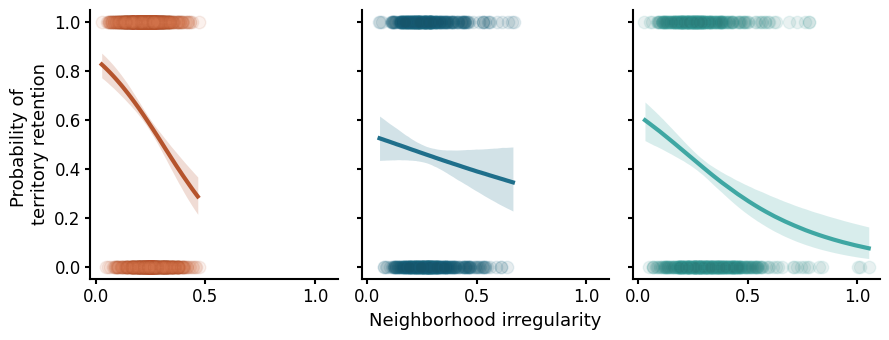

In [9]:
fig,axes = plt.subplots(1, 3, figsize=(9, 3.5), sharex=True, sharey=True)

for i, lek in enumerate(lek_levels):
    ax = axes[i]
    df_lek = df[df['lek_id'] == lek]

    transition_ix = np.sort(df_lek['transition_id'].unique()) - 1
    transition_stats = df_lek.groupby('transition_id')['six_neighbour_cv'].agg(['mean', 'std', 'size'])
    cv_mask = (cv_original >= df_lek['six_neighbour_cv'].min()) & (cv_original <= df_lek['six_neighbour_cv'].max())

    # Compute posterior retention probabilities
    mu = (fit['alpha_transition'][transition_ix, :, None]
          + fit['beta'][i, None, :, None] * (cv_original[None, None, :] - transition_stats['mean'].to_numpy()[:, None, None]) / transition_stats['std'].to_numpy()[:, None, None])
    p_transitions = scipy.special.expit(mu)

    # Weight transitions by their number of observed territories
    y = np.average(p_transitions, axis=0, weights=transition_stats['size'].to_numpy())
    y_median = np.median(y, axis=0)
    y_lower,y_upper = np.quantile(y, [0.025,0.975], axis=0)

    # Plot model fits
    ax.plot(cv_original[cv_mask], y_median[cv_mask], linewidth=3, color=fill_cols[lek], label=lek)
    ax.fill_between(cv_original[cv_mask], y_lower[cv_mask], y_upper[cv_mask], color=fill_cols[lek], alpha=0.2, linewidth=0)

    # Add scatter to the plot
    ax.scatter(df_lek['six_neighbour_cv'], df_lek['persistent'], s=80, color=point_cols[lek], edgecolor=fill_cols[lek], alpha=0.1, zorder=4)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)


axes[1].set_xlabel('Neighborhood irregularity', fontsize=13)
axes[0].set_ylabel('Probability of \nterritory retention', fontsize=13)

plt.tight_layout()
plt.savefig(out_dir/'mod_territory_retention.png', dpi=300, bbox_inches='tight')

In [10]:
## Compute the change in retention probability for each lek
p_retention = np.empty((len(lek_levels), fit['beta'].shape[1]))

for i, lek in enumerate(lek_levels):
    df_lek = df[df['lek_id'] == lek]
    transition_ix = np.sort(df_lek['transition_id'].unique()) - 1
    transition_weights = df_lek.groupby('transition_id').size().to_numpy()
    transition_weights = transition_weights / transition_weights.sum()
    change = (scipy.special.expit(fit['alpha_transition'][transition_ix, :] + 0.5 * fit['beta'][i, :])
              - scipy.special.expit(fit['alpha_transition'][transition_ix, :] - 0.5 * fit['beta'][i, :]))
    p_retention[i, :] = np.average(change, axis=0, weights=transition_weights)

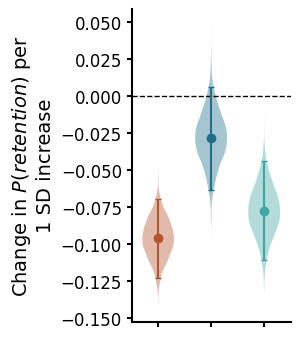

In [11]:
fig, ax = plt.subplots(figsize=(3, 3.5))

## x-positions for categorical variables
x_pos = np.arange(len(lek_levels))

for i,lek in enumerate(lek_levels):
    samples = p_retention[i,:]

    # Violin plot
    parts = ax.violinplot(samples, positions=[x_pos[i]], widths=0.6, showmeans=False, showmedians=False, showextrema=False)

    for pc in parts['bodies']:
        pc.set_facecolor(fill_cols.get(lek))
        pc.set_edgecolor('none')
        pc.set_alpha(0.4)

    # Overlay median and posterior interval
    median = np.median(samples)
    lower, upper = np.quantile(samples, [0.025, 0.975])

    ax.errorbar(x_pos[i], median, yerr=[[median-lower], [upper-median]], fmt='o', color=fill_cols.get(lek), markersize=6, capsize=2, zorder=3)

ax.axhline(0, linestyle='--', color='black', linewidth=1)
ax.set_xlim(-0.5, len(lek_levels) - 0.5)
ax.set_xticks(x_pos)
ax.set_xticklabels([])

ax.set_ylabel('Change in $P(retention)$ per \n1 SD increase', fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)
ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)

plt.tight_layout()
plt.savefig(out_dir/'mod_causal_selective_retention.png', dpi=300, bbox_inches='tight')

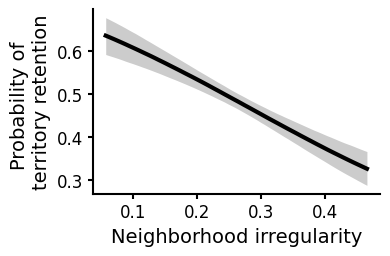

In [12]:
fig, ax = plt.subplots(figsize=(4, 8/3))

pooled_pred = np.zeros((fit['beta'].shape[1], len(cv_original)))

for i, lek in enumerate(lek_levels):
    df_lek = df[df['lek_id'] == lek]

    transition_idx = np.sort(df_lek['transition_id'].unique()) - 1
    transition_stats = df_lek.groupby('transition_id')['six_neighbour_cv'].agg(['mean', 'std', 'size'])

    # Compute posterior retention probabilities
    mu = (fit['alpha_transition'][transition_idx, :, None]
          + fit['beta'][i, None, :, None] * (cv_original[None, None, :] - transition_stats['mean'].to_numpy()[:, None, None]) / transition_stats['std'].to_numpy()[:, None, None])
    p_transitions = scipy.special.expit(mu)

    # Weight transitions by number of territories, sites equally
    y = np.average(p_transitions, axis=0, weights=transition_stats['size'].to_numpy())
    pooled_pred += y / len(lek_levels)

# Posterior summaries
y_median = np.median(pooled_pred, axis=0)
y_lower, y_upper = np.quantile(pooled_pred, [0.025, 0.975], axis=0)

# Restrict to CV range shared across sites
cv_min = max(df.loc[df['lek_id'] == lek, 'six_neighbour_cv'].min() for lek in lek_levels)
cv_max = min(df.loc[df['lek_id'] == lek, 'six_neighbour_cv'].max() for lek in lek_levels)
cv_mask = (cv_original >= cv_min) & (cv_original <= cv_max)

# Plot
ax.plot(cv_original[cv_mask], y_median[cv_mask], linewidth=3, color='black')
ax.fill_between(cv_original[cv_mask], y_lower[cv_mask], y_upper[cv_mask], color='black', alpha=0.2, linewidth=0)

ax.set_xlabel('Neighborhood irregularity', fontsize=14)
ax.set_ylabel('Probability of \nterritory retention', fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)
ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)

plt.tight_layout()
plt.savefig(out_dir/'mod_territory_retention_pooled.png', dpi=300, bbox_inches='tight')